#### Data

The dataset is at `solutions/galaxyquasar.csv`. I have extracted it myself from the SDSS database using the SQL query reported [here](https://www.astroml.org/_modules/astroML/datasets/sdss_galaxy_colors.html#fetch_sdss_galaxy_colors)

(If you've never used [SQL](https://en.wikipedia.org/wiki/SQL) and want to learn something new in computing, it's very powerful)

#### Tasks

- Create arrays for the $(u-g)$, $(g-r)$, $(r-i)$, and $(i-z)$ colors. Also create an array with the class labels where galaxy=$0$ and quasar=$1$. 
- Classify the dataset against the target label.
- Try some of the classification methods we've seen so far and evaluate the performance using the ROC curve.
- Remember to split the dataset into training and validation...

#### Ideas
- Try using different colors (a subset of them first, than all together). Which is the most important feature?
- What are the colors that better satisfy or invalidate the "Naive" assumption of independence between the attributes?


In [10]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
file = pd.read_csv("C:/Users/user/Desktop/astrostatistics_bicocca_2026/solutions/galaxyquasar.csv")

file['u-g'] = file['u'] - file['g']
file['g-r'] = file['g'] - file['r']
file['r-i'] = file['r'] - file['i']
file['i-z'] = file['i'] - file['z']
colors = ['u-g', 'g-r', 'r-i', 'i-z']

X = file[colors].values
y = (file['class'] == 'QSO').astype(int).values   # GALAXY=0, QSO=1
print(file['class'].value_counts())

class
GALAXY    42866
QSO        7134
Name: count, dtype: int64


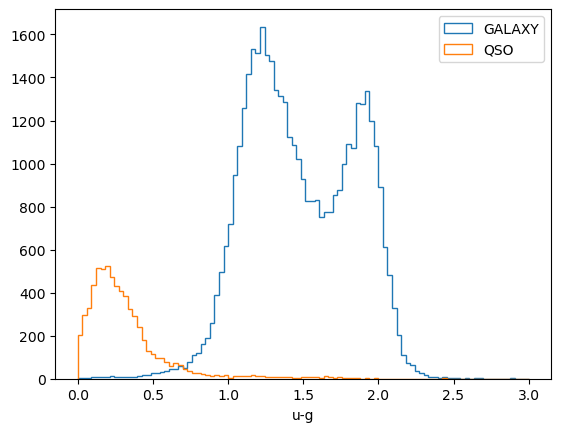

In [11]:
plt.hist(file.loc[y==0, 'u-g'], bins=np.linspace(0, 3, 100), histtype='step', label='GALAXY')
plt.hist(file.loc[y==1, 'u-g'], bins=np.linspace(0, 3, 100), histtype='step', label='QSO')
plt.legend(); plt.xlabel('u-g');

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

GNB: AUC = 0.9744
[[12610   250]
 [  180  1960]]
LDA: AUC = 0.9795
[[12737   123]
 [  171  1969]]
QDA: AUC = 0.9815
[[12719   141]
 [  176  1964]]


c:\Users\user\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\user\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\user\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\user\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\user\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(

GMMBayes (4): AUC = 0.9895
[[12737   123]
 [  167  1973]]
KNN (k=7): AUC = 0.9835
[[12772    88]
 [  143  1997]]


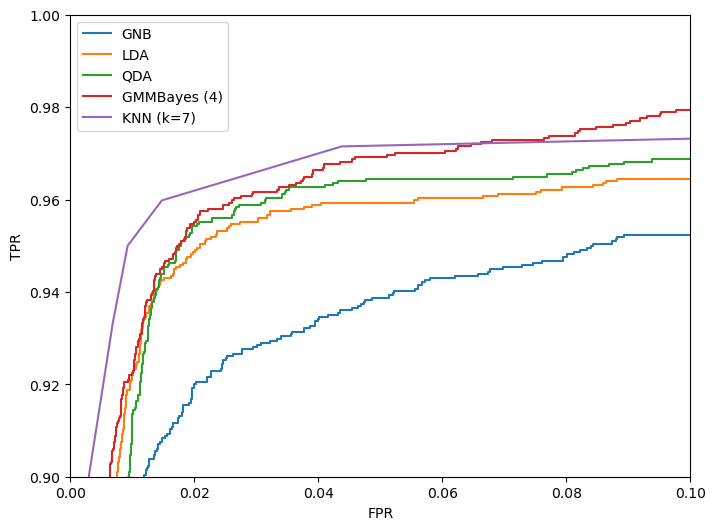

In [13]:
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from astroML.classification import GMMBayes
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, classification_report

models = {
    'GNB': GaussianNB(),
    'LDA': LinearDiscriminantAnalysis(),
    'QDA': QuadraticDiscriminantAnalysis(),
    'GMMBayes (4)': GMMBayes(n_components=4),
    'KNN (k=7)': KNeighborsClassifier(n_neighbors=7),
}

plt.figure(figsize=(8, 6))
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, p)
    print(f"{name}: AUC = {roc_auc_score(y_val, p):.4f}")
    print(confusion_matrix(y_val, m.predict(X_val)))
    plt.plot(fpr, tpr, label=name)
plt.xlim(0, 0.1); plt.ylim(0.9, 1)      # zoom sull'angolo alto-sinistra
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.legend();

In [14]:
for i, c in enumerate(colors):
    g = GaussianNB().fit(X_train[:, [i]], y_train)
    p = g.predict_proba(X_val[:, [i]])[:, 1]
    print(f"{c}: AUC = {roc_auc_score(y_val, p):.4f}")

g = GaussianNB().fit(X_train, y_train)
print("tutti:", roc_auc_score(y_val, g.predict_proba(X_val)[:, 1]))

u-g: AUC = 0.9805
g-r: AUC = 0.9370
r-i: AUC = 0.8971
i-z: AUC = 0.8372
tutti: 0.974432893417247


In [15]:
print(file[colors].corr().round(2))
for lab, name in [(0, 'GALAXY'), (1, 'QSO')]:
    print(name); print(file.loc[y==lab, colors].corr().round(2))

      u-g   g-r   r-i   i-z
u-g  1.00  0.80  0.47  0.36
g-r  0.80  1.00  0.35  0.32
r-i  0.47  0.35  1.00 -0.16
i-z  0.36  0.32 -0.16  1.00
GALAXY
      u-g   g-r   r-i   i-z
u-g  1.00  0.74  0.34  0.31
g-r  0.74  1.00  0.24  0.24
r-i  0.34  0.24  1.00 -0.25
i-z  0.31  0.24 -0.25  1.00
QSO
      u-g   g-r   r-i   i-z
u-g  1.00  0.37  0.20  0.12
g-r  0.37  1.00 -0.04  0.16
r-i  0.20 -0.04  1.00 -0.38
i-z  0.12  0.16 -0.38  1.00
